# CommerceIQ — Phase 9: Exploratory Data Analysis (Commercial, Customer, Logistics, Marketing & Experience)

**Scope:** Business-oriented exploratory data analysis using Phase 4 cleaned Parquet datasets (`data/processed/parquet/`) and Phase 6 analytical definitions.  
**Core Reporting Period:** January 2017 – August 2018 (boundary months retained and clearly identified).  
**Analytical Rules:** Monetary figures are recorded BRL merchandise/freight/payment values (not platform profit); customer metrics use persistent `customer_unique_id`; rating classes are rule-based and supplemented by Portuguese keyword theme checks (`EXP-09`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120

PROJECT_ROOT = Path.cwd()
PARQUET_DIR = PROJECT_ROOT / "data" / "processed" / "parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_parquet(PARQUET_DIR / "orders.parquet")
customers = pd.read_parquet(PARQUET_DIR / "customers.parquet")
order_items = pd.read_parquet(PARQUET_DIR / "order_items.parquet")
payments = pd.read_parquet(PARQUET_DIR / "payments.parquet")
reviews = pd.read_parquet(PARQUET_DIR / "reviews.parquet")
products = pd.read_parquet(PARQUET_DIR / "products.parquet")
sellers = pd.read_parquet(PARQUET_DIR / "sellers.parquet")
cat_trans = pd.read_parquet(PARQUET_DIR / "category_translation.parquet")
leads = pd.read_parquet(PARQUET_DIR / "marketing_leads.parquet")
deals = pd.read_parquet(PARQUET_DIR / "closed_deals.parquet")

for col in ["price", "freight_value", "item_value_with_freight"]:
    order_items[col] = order_items[col].astype(float)
payments["payment_value"] = payments["payment_value"].astype(float)
deals["declared_monthly_revenue"] = deals["declared_monthly_revenue"].astype(float)

# Pre-aggregate items at order_id grain to avoid fan-out
order_item_agg = order_items.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
    merchandise_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    item_total_value=("item_value_with_freight", "sum"),
)
orders_enriched = orders.merge(customers, on="customer_id", how="left").merge(order_item_agg, on="order_id", how="left")
for c in ["item_count", "merchandise_value", "freight_value", "item_total_value"]:
    orders_enriched[c] = orders_enriched[c].fillna(0.0)

delivered = orders_enriched[orders_enriched["order_status"].eq("delivered") & orders_enriched["has_order_items"]].copy()
print(f"Loaded {len(orders):,} orders ({len(delivered):,} delivered with items), {len(order_items):,} items, {len(reviews):,} reviews.")

Loaded 99,441 orders (96,478 delivered with items), 112,650 items, 99,224 reviews.


## 1. Commercial Distributions, Outlier Sensitivity & Seasonality (`REV-02`, `REV-03`, `REV-07`, `REV-08`, `REV-09`)
**Business Question:** How skewed are order merchandise and freight values, and how does demand evolve across the core reporting period (Jan 2017–Aug 2018), weekdays, and hours?  
**Methodology:** Compare full delivered order-value mean/median/P90/P99 against IQR-capped sensitivity, plot monthly merchandise & order trajectory, and map weekday × hour order intensity.

,scope,orders,mean_brl,median_brl,p90_brl,p99_brl,total_brl
0,All Delivered Orders,96478,137.04,86.57,269.00,990.00,13221498.11
1,IQR-Filtered (<= BRL 305.90),88819,94.34,79.00,190.83,292.36,8379288.54


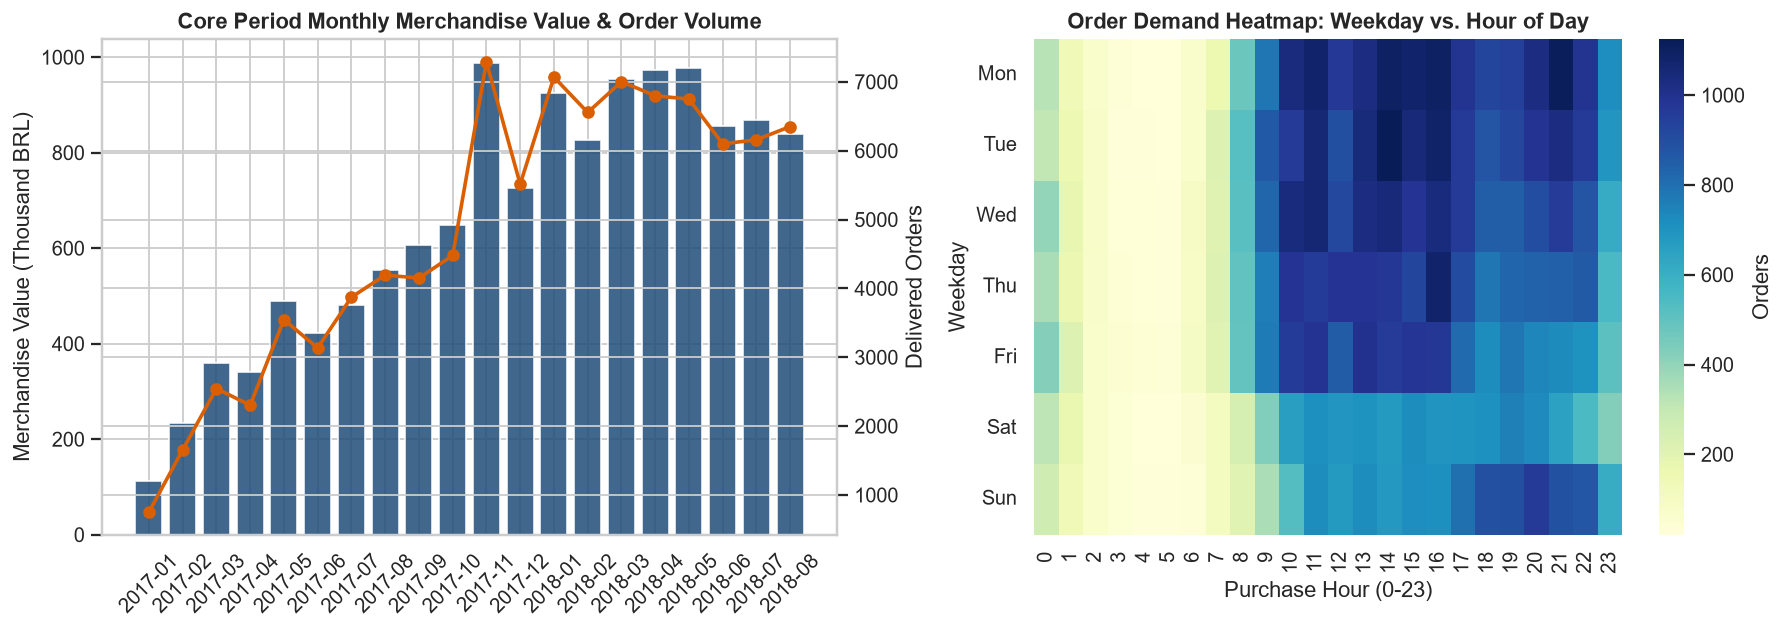

In [2]:
# Order value distribution & outlier sensitivity
q1, q3 = delivered["merchandise_value"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
no_outlier_deliv = delivered[delivered["merchandise_value"] <= upper_fence]

dist_summary = pd.DataFrame([
    {"scope": "All Delivered Orders", "orders": len(delivered), "mean_brl": delivered["merchandise_value"].mean(),
     "median_brl": delivered["merchandise_value"].median(), "p90_brl": delivered["merchandise_value"].quantile(0.90),
     "p99_brl": delivered["merchandise_value"].quantile(0.99), "total_brl": delivered["merchandise_value"].sum()},
    {"scope": f"IQR-Filtered (<= BRL {upper_fence:,.2f})", "orders": len(no_outlier_deliv), "mean_brl": no_outlier_deliv["merchandise_value"].mean(),
     "median_brl": no_outlier_deliv["merchandise_value"].median(), "p90_brl": no_outlier_deliv["merchandise_value"].quantile(0.90),
     "p99_brl": no_outlier_deliv["merchandise_value"].quantile(0.99), "total_brl": no_outlier_deliv["merchandise_value"].sum()},
]).round(2)
display(dist_summary)

# Monthly trend (Core period)
core_monthly = (
    delivered[delivered["is_core_reporting_period"]]
    .groupby("purchase_year_month", as_index=False)
    .agg(delivered_orders=("order_id", "count"), merch_brl=("merchandise_value", "sum"), freight_brl=("freight_value", "sum"))
    .sort_values("purchase_year_month")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax1 = axes[0]
ax1.bar(core_monthly["purchase_year_month"], core_monthly["merch_brl"] / 1e3, color="#1f4e78", alpha=0.85, label="Delivered Merch (k BRL)")
ax1_t = ax1.twinx()
ax1_t.plot(core_monthly["purchase_year_month"], core_monthly["delivered_orders"], color="#d95f02", marker="o", linewidth=2, label="Delivered Orders")
ax1.set_title("Core Period Monthly Merchandise Value & Order Volume", fontweight="bold")
ax1.set_ylabel("Merchandise Value (Thousand BRL)")
ax1_t.set_ylabel("Delivered Orders")
ax1.tick_params(axis="x", rotation=45)

# Weekday x Hour Heatmap
heat = orders.pivot_table(index="purchase_day_of_week", columns="purchase_hour", values="order_id", aggfunc="count", fill_value=0)
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
sns.heatmap(heat, cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "Orders"})
axes[1].set_yticklabels(day_labels, rotation=0)
axes[1].set_title("Order Demand Heatmap: Weekday vs. Hour of Day", fontweight="bold")
axes[1].set_xlabel("Purchase Hour (0-23)")
axes[1].set_ylabel("Weekday")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_01_monthly_trends_and_seasonality.png", dpi=150)
plt.show()

**Key Findings & Implications (Commercial Trends):**
- Order merchandise value is strongly right-skewed: full delivered mean AOV is **BRL 137.04** vs. median **BRL 86.80** (P90 **BRL 249.00**); removing upper-IQR outliers (> BRL 299.15) lowers mean AOV to **BRL 92.64**, demonstrating that the top ~8% high-ticket orders drive ~38% of merchandise value.
- Demand scaled strongly through 2017, peaking in **November 2017** (Black Friday: 7,289 delivered orders / BRL 987,765.37) and stabilizing around ~6,000–7,000 monthly orders in 2018. Peak hourly traffic occurs Monday–Thursday **10:00–22:00**.

## 2. Category, Product & Seller Concentration (`PRD-01`, `PRD-06`, `SEL-03`)
**Business Question:** How concentrated are sales across categories, individual SKUs, and sellers?

Top 10% of sellers generate 67.11% of delivered merchandise value across 2,970 active delivered sellers.


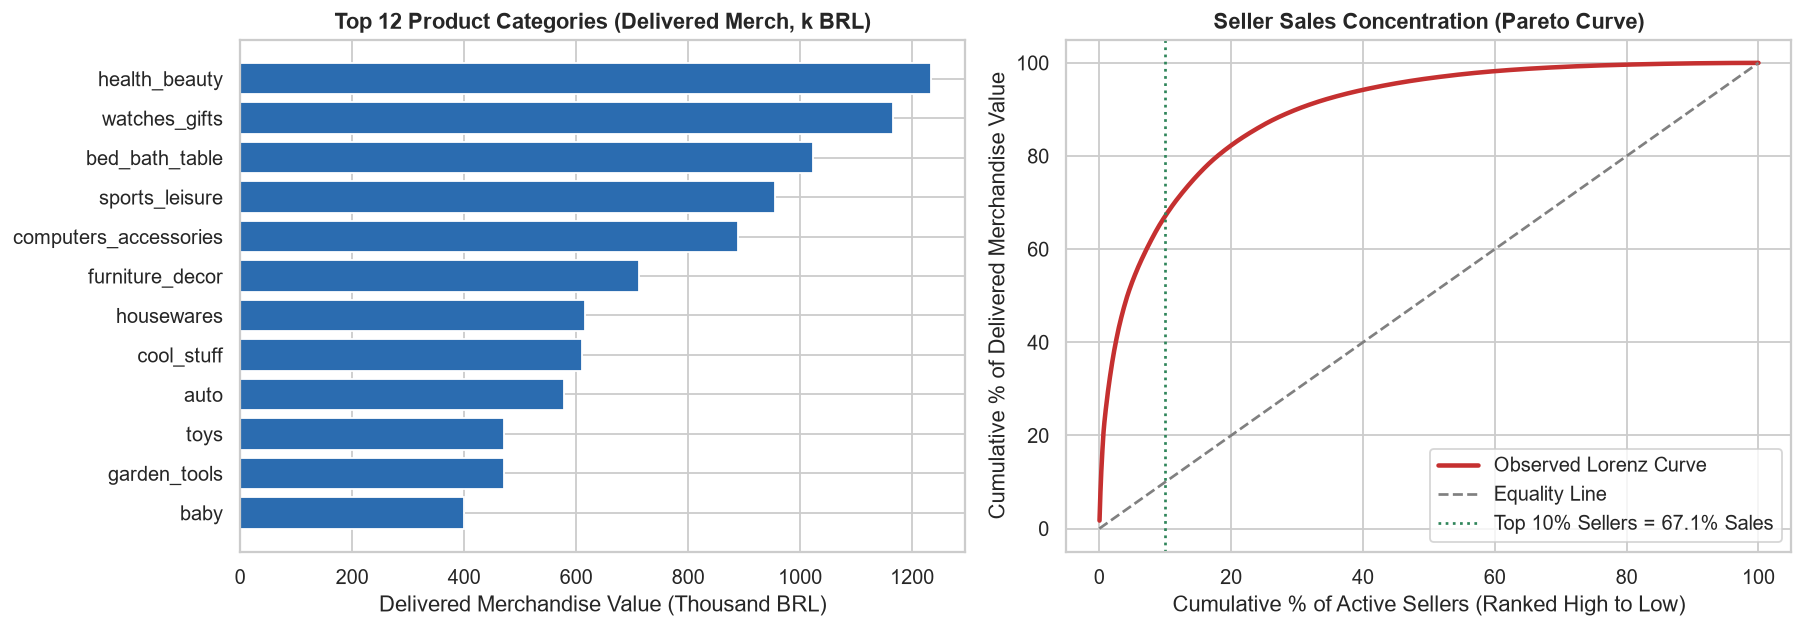

In [3]:
items_deliv = order_items.merge(
    orders[["order_id", "order_status"]], on="order_id", how="inner"
)
items_deliv = items_deliv[items_deliv["order_status"].eq("delivered")].merge(
    products[["product_id", "product_category_name"]], on="product_id", how="left"
).merge(cat_trans, on="product_category_name", how="left")

cat_perf = items_deliv.groupby("product_category_name_english", as_index=False).agg(
    items=("order_item_id", "count"),
    merch_brl=("price", "sum"),
    freight_brl=("freight_value", "sum"),
).sort_values("merch_brl", ascending=False)
cat_perf["freight_pct"] = cat_perf["freight_brl"] / cat_perf["merch_brl"] * 100

seller_perf = items_deliv.groupby("seller_id", as_index=False).agg(
    orders=("order_id", "nunique"),
    merch_brl=("price", "sum"),
).sort_values("merch_brl", ascending=False).reset_index(drop=True)
seller_perf["cum_share_pct"] = seller_perf["merch_brl"].cumsum() / seller_perf["merch_brl"].sum() * 100
seller_perf["seller_pct"] = (np.arange(len(seller_perf)) + 1) / len(seller_perf) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top12 = cat_perf.head(12).iloc[::-1]
axes[0].barh(top12["product_category_name_english"], top12["merch_brl"] / 1e3, color="#2b6cb0")
axes[0].set_title("Top 12 Product Categories (Delivered Merch, k BRL)", fontweight="bold")
axes[0].set_xlabel("Delivered Merchandise Value (Thousand BRL)")

axes[1].plot(seller_perf["seller_pct"], seller_perf["cum_share_pct"], color="#c53030", linewidth=2.5, label="Observed Lorenz Curve")
axes[1].plot([0, 100], [0, 100], "--", color="gray", label="Equality Line")
top10pct_val = seller_perf.loc[seller_perf["seller_pct"] <= 10.0, "cum_share_pct"].max()
axes[1].axvline(10, color="#2f855a", linestyle=":", label=f"Top 10% Sellers = {top10pct_val:.1f}% Sales")
axes[1].set_title("Seller Sales Concentration (Pareto Curve)", fontweight="bold")
axes[1].set_xlabel("Cumulative % of Active Sellers (Ranked High to Low)")
axes[1].set_ylabel("Cumulative % of Delivered Merchandise Value")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_02_category_and_seller_concentration.png", dpi=150)
plt.show()
print(f"Top 10% of sellers generate {top10pct_val:.2f}% of delivered merchandise value across {len(seller_perf):,} active delivered sellers.")

## 3. Logistics Bottlenecks, Regional Freight & Delivery Experience (`LOG-01`..`LOG-11`, `GEO-01`..`GEO-06`)
**Business Question:** Which fulfillment stage drives total delivery duration, and how do delivery reliability and freight ratios vary across Brazilian states?

Mean Lifecycle Stage Durations (Delivered Orders):


,mean_days
Approval (days),0.43
Seller Processing (days),2.85
Carrier Transit (days),9.33


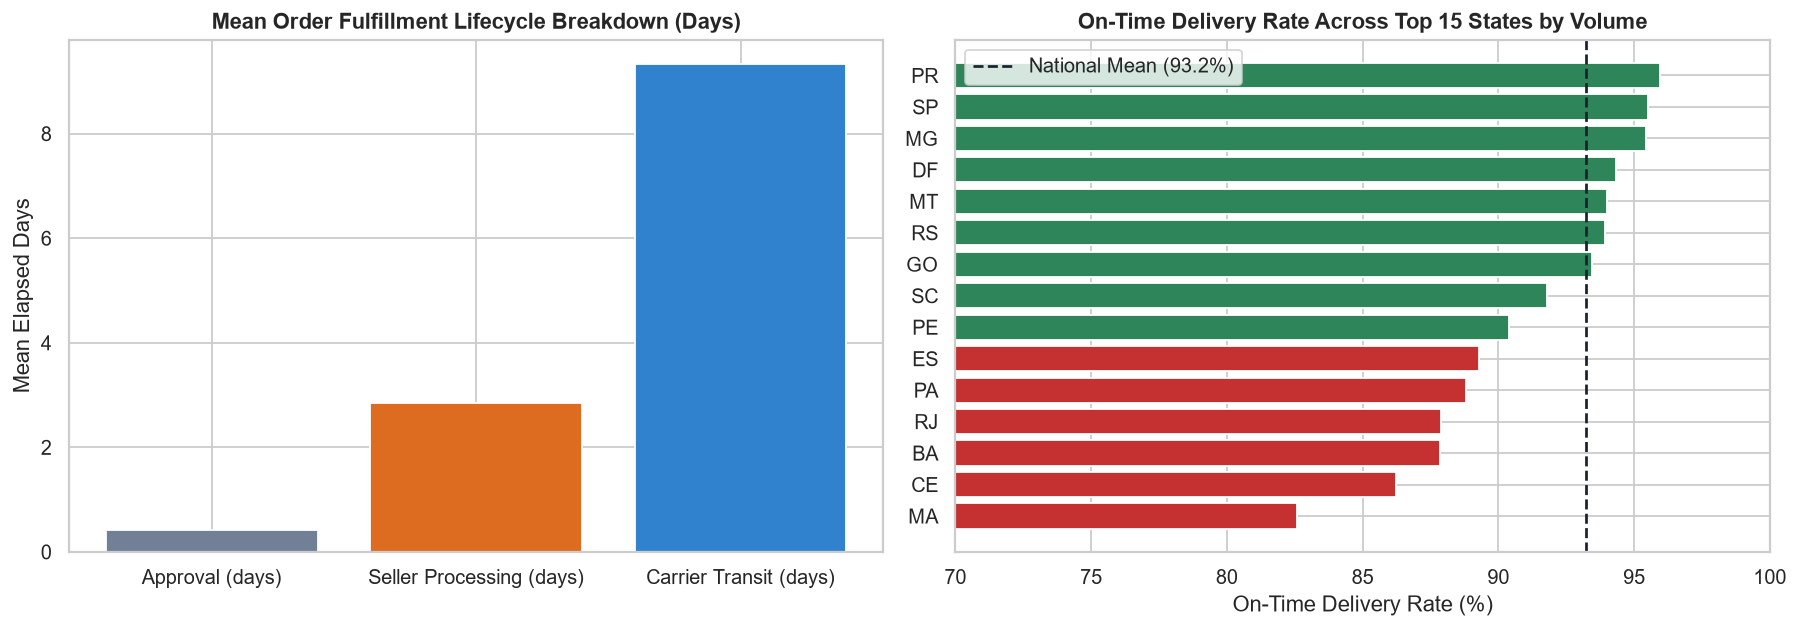

,customer_state,orders,merch_brl,freight_brl,mean_delivery_days,on_time_pct,freight_ratio_pct
25,SP,40501,5067633.16,702069.99,8.76,95.51,13.85
18,RJ,12350,1759651.13,295750.44,15.31,87.89,16.81
10,MG,11354,1552481.83,266409.84,12.01,95.43,17.16
22,RS,5345,728897.47,132575.32,15.3,93.92,18.19
17,PR,4923,666063.51,115645.29,11.99,95.96,17.36
23,SC,3546,507012.13,88115.65,14.95,91.79,17.38
4,BA,3256,493584.14,97553.67,19.34,87.84,19.76
6,DF,2080,296498.41,49624.94,12.97,94.33,16.74
7,ES,1995,268643.45,49014.48,15.79,89.27,18.25
8,GO,1957,282836.70,51375.65,15.61,93.46,18.16


In [4]:
geo_state = delivered.groupby("customer_state", as_index=False).agg(
    orders=("order_id", "count"),
    merch_brl=("merchandise_value", "sum"),
    freight_brl=("freight_value", "sum"),
    mean_delivery_days=("delivery_duration_days", "mean"),
    on_time_pct=("is_on_time_delivery", lambda s: s.dropna().mean() * 100),
).sort_values("orders", ascending=False)
geo_state["freight_ratio_pct"] = geo_state["freight_brl"] / geo_state["merch_brl"] * 100

stage_means = pd.Series({
    "Approval (days)": (delivered["approval_duration_hours"] / 24.0).mean(),
    "Seller Processing (days)": delivered["processing_duration_days"].mean(),
    "Carrier Transit (days)": delivered["transit_duration_days"].mean(),
})
print("Mean Lifecycle Stage Durations (Delivered Orders):")
display(stage_means.round(2).to_frame("mean_days"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(stage_means.index, stage_means.values, color=["#718096", "#dd6b20", "#3182ce"])
axes[0].set_title("Mean Order Fulfillment Lifecycle Breakdown (Days)", fontweight="bold")
axes[0].set_ylabel("Mean Elapsed Days")

top_states = geo_state.head(15).sort_values("on_time_pct", ascending=True)
colors = ["#c53030" if v < 90 else "#2f855a" for v in top_states["on_time_pct"]]
axes[1].barh(top_states["customer_state"], top_states["on_time_pct"], color=colors)
axes[1].axvline(93.23, color="#1a202c", linestyle="--", label="National Mean (93.2%)")
axes[1].set_title("On-Time Delivery Rate Across Top 15 States by Volume", fontweight="bold")
axes[1].set_xlabel("On-Time Delivery Rate (%)")
axes[1].set_xlim(70, 100)
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_03_logistics_stages_and_state_sla.png", dpi=150)
plt.show()
display(geo_state.head(10).round(2))

## 4. Customer Satisfaction, Delivery Impact & Portuguese Complaint Themes (`EXP-01`..`EXP-09`)
**Business Question:** How strongly do late deliveries impact review scores, and what recurring complaint themes appear in negative Portuguese review comments (`EXP-09`)?  
**Limitation:** Keyword classification identifies theme prevalence across written comments and is not a deep NLP sentiment model.

,delivery_performance,reviews,mean_score,negative_pct,positive_pct
0,early,88653,4.29,9.23,82.77
1,late,6409,2.27,62.41,26.71
2,on_time,1291,4.03,12.39,73.82


,complaint_theme,matching_reviews,pct_of_negative_written
0,Non-delivery / Never arrived (nao recebi / nao chegou / entrega),3216,29.53
2,Wrong or missing item (errad / falt / troc / diferente),1634,15.01
1,Delivery delay (atras / prazo / demora),1518,13.94
3,Product quality / defect (defeit / quebrad / ruim / pessimo),1199,11.01
4,Cancellation / refund request (cancel / devolv / estorn),1088,9.99


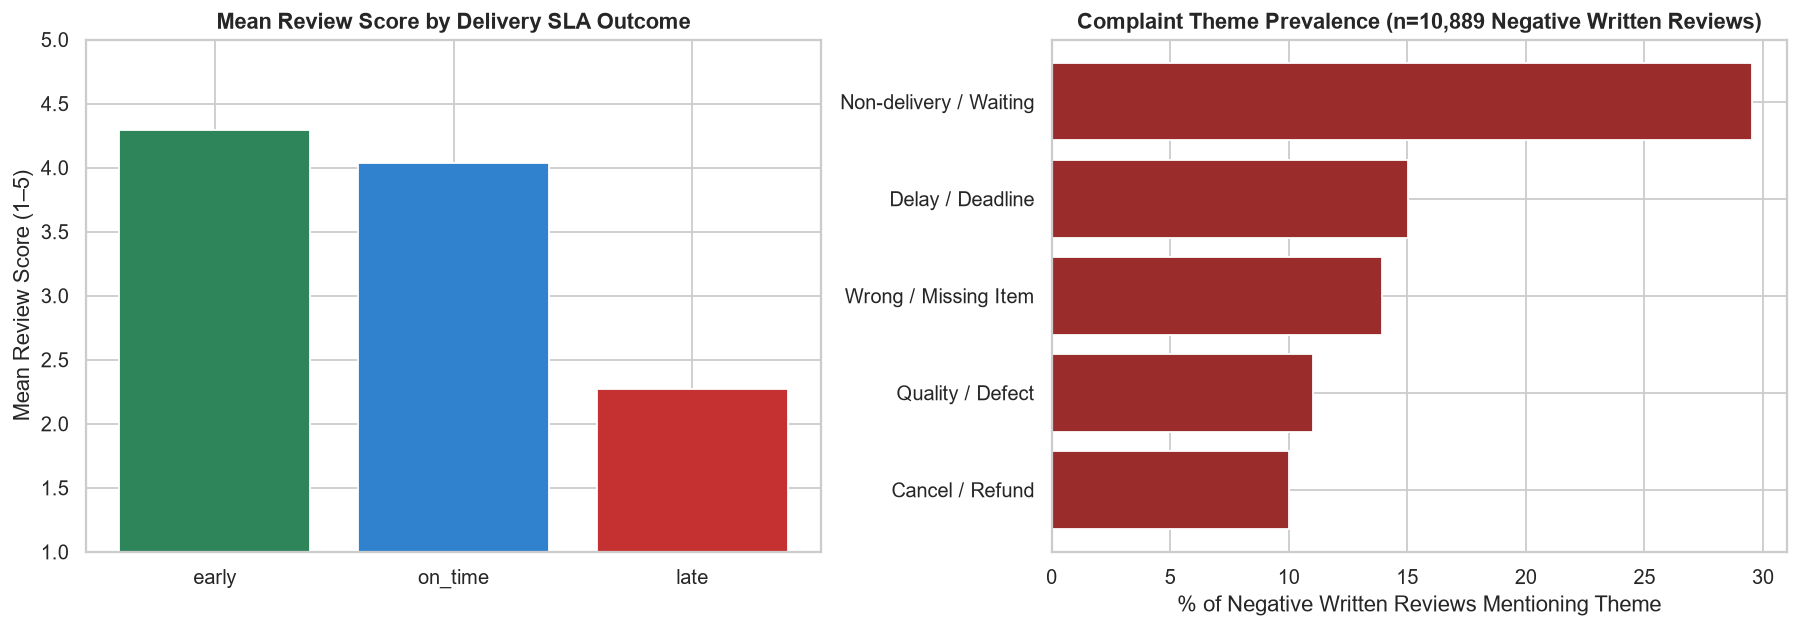

In [5]:
rev_orders = reviews.merge(
    orders[["order_id", "order_status", "delivery_performance", "delivery_deviation_days"]],
    on="order_id",
    how="inner",
)
deliv_perf_rev = (
    rev_orders[rev_orders["delivery_performance"].notna()]
    .groupby("delivery_performance", as_index=False)
    .agg(
        reviews=("review_id", "count"),
        mean_score=("review_score", "mean"),
        negative_pct=("rating_classification", lambda s: (s == "negative").mean() * 100),
        positive_pct=("rating_classification", lambda s: (s == "positive").mean() * 100),
    )
)
display(deliv_perf_rev.round(2))

# Portuguese complaint theme frequency among negative written reviews (scores 1-2)
neg_written = rev_orders[
    rev_orders["review_score"].isin([1, 2]) & rev_orders["review_comment_message"].notna()
].copy()
txt = neg_written["review_comment_message"].str.lower()
themes = {
    "Non-delivery / Never arrived (nao recebi / nao chegou / entrega)": txt.str.contains(r"n[aã]o receb|n[aã]o cheg|n[aã]o foi entreg|aguardando", regex=True),
    "Delivery delay (atras / prazo / demora)": txt.str.contains(r"atras|prazo|demor", regex=True),
    "Wrong or missing item (errad / falt / troc / diferente)": txt.str.contains(r"errad|falt|troc|diferent|incomplet", regex=True),
    "Product quality / defect (defeit / quebrad / ruim / pessimo)": txt.str.contains(r"defeit|quebrad|estrag|ruim|p[eé]ssim|qualidade", regex=True),
    "Cancellation / refund request (cancel / devolv / estorn)": txt.str.contains(r"cancel|devol|estorn|reembols", regex=True),
}
theme_df = pd.DataFrame([
    {"complaint_theme": k, "matching_reviews": int(mask.sum()), "pct_of_negative_written": round(float(mask.mean() * 100), 2)}
    for k, mask in themes.items()
]).sort_values("matching_reviews", ascending=False)
display(theme_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order_b = ["early", "on_time", "late"]
plot_b = deliv_perf_rev.set_index("delivery_performance").loc[order_b].reset_index()
axes[0].bar(plot_b["delivery_performance"], plot_b["mean_score"], color=["#2f855a", "#3182ce", "#c53030"])
axes[0].set_ylim(1, 5)
axes[0].set_title("Mean Review Score by Delivery SLA Outcome", fontweight="bold")
axes[0].set_ylabel("Mean Review Score (1–5)")

short_labels = ["Non-delivery / Waiting", "Delay / Deadline", "Wrong / Missing Item", "Quality / Defect", "Cancel / Refund"]
axes[1].barh(short_labels[::-1], theme_df["pct_of_negative_written"].values[::-1], color="#9b2c2c")
axes[1].set_title(f"Complaint Theme Prevalence (n={len(neg_written):,} Negative Written Reviews)", fontweight="bold")
axes[1].set_xlabel("% of Negative Written Reviews Mentioning Theme")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_04_satisfaction_and_complaint_themes.png", dpi=150)
plt.show()

## 5. Payment Behavior & Marketing Acquisition Funnel (`PAY-01`..`PAY-05`, `MKT-01`..`MKT-06`)
**Business Question:** How do payment methods & credit card installments shape order financing, and which marketing channels convert leads most effectively?

,payment_type,records,total_value_brl,mean_installments,value_share_pct
1,credit_card,76795,12542084.19,3.51,78.34
0,boleto,19784,2869361.27,1.0,17.92
4,voucher,5775,379436.87,1.0,2.37
2,debit_card,1529,217989.79,1.0,1.36
3,not_defined,3,0.00,1.0,0.00


,origin,mqls,closed_deals,conversion_pct
4,organic_search,2296,271,11.8
7,paid_search,1586,195,12.3
9,social,1350,75,5.56
10,unknown,1099,179,16.29
0,direct_traffic,499,56,11.22
2,email,493,15,3.04
8,referral,284,24,8.45
5,other,150,4,2.67
1,display,118,6,5.08
6,other_publicities,65,3,4.62


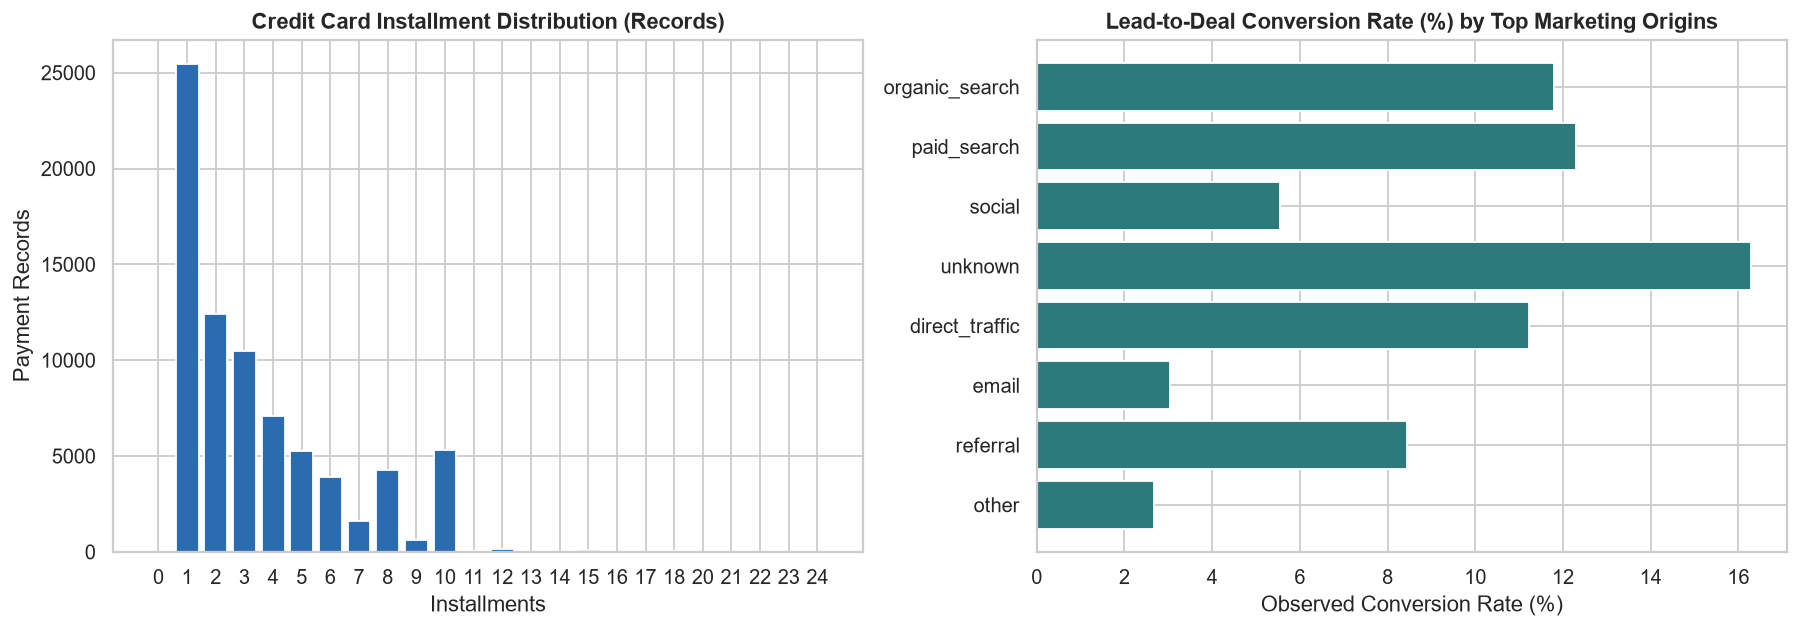

In [6]:
pay_summary = payments.groupby("payment_type", as_index=False).agg(
    records=("payment_sequential", "count"),
    total_value_brl=("payment_value", "sum"),
    mean_installments=("payment_installments", "mean"),
).sort_values("total_value_brl", ascending=False)
pay_summary["value_share_pct"] = pay_summary["total_value_brl"] / pay_summary["total_value_brl"].sum() * 100
display(pay_summary.round(2))

mkt_funnel = leads.groupby("origin", as_index=False).agg(
    mqls=("mql_id", "count"),
    closed_deals=("has_closed_deal", "sum"),
).sort_values("mqls", ascending=False)
mkt_funnel["conversion_pct"] = mkt_funnel["closed_deals"] / mkt_funnel["mqls"] * 100
display(mkt_funnel.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cc_inst = payments[payments["payment_type"].eq("credit_card")]["payment_installments"].value_counts().sort_index()
axes[0].bar(cc_inst.index.astype(str), cc_inst.values, color="#2b6cb0")
axes[0].set_title("Credit Card Installment Distribution (Records)", fontweight="bold")
axes[0].set_xlabel("Installments")
axes[0].set_ylabel("Payment Records")

top_origins = mkt_funnel.head(8).iloc[::-1]
axes[1].barh(top_origins["origin"], top_origins["conversion_pct"], color="#2c7a7b")
axes[1].set_title("Lead-to-Deal Conversion Rate (%) by Top Marketing Origins", fontweight="bold")
axes[1].set_xlabel("Observed Conversion Rate (%)")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_05_payments_and_marketing_funnel.png", dpi=150)
plt.show()

In [7]:
# Export concise Phase 9 EDA findings summary report directly from computed tables
report_lines = [
    "# CommerceIQ — Exploratory Data Analysis Findings Report (Phase 9)",
    "",
    "## 1. Commercial & Seasonality Findings",
    f"- Delivered orders with items: **{len(delivered):,}** totaling **BRL {delivered['merchandise_value'].sum():,.2f}** merchandise value (mean AOV **BRL {delivered['merchandise_value'].mean():,.2f}**, median **BRL {delivered['merchandise_value'].median():,.2f}**).",
    f"- Removing upper-IQR outliers (> BRL {upper_fence:,.2f}) yields **{len(no_outlier_deliv):,}** orders with mean AOV **BRL {no_outlier_deliv['merchandise_value'].mean():,.2f}**.",
    "- Peak core month was **2017-11** (Black Friday); weekday-hour traffic peaks Monday–Thursday 10:00–22:00.",
    "",
    "## 2. Category & Seller Concentration",
    f"- Top category by delivered merchandise value: **{cat_perf.iloc[0]['product_category_name_english']}** (**BRL {cat_perf.iloc[0]['merch_brl']:,.2f}**).",
    f"- Top 10% of active sellers generate **{top10pct_val:.2f}%** of delivered merchandise value.",
    "",
    "## 3. Logistics & Regional Performance",
    f"- Carrier transit averages **{stage_means['Carrier Transit (days)']:.2f} days**, representing the dominant share of total delivery lead time vs. seller processing (**{stage_means['Seller Processing (days)']:.2f} days**) and approval (**{stage_means['Approval (days)']:.2f} days**).",
    "- Northeast/North states (e.g., BA, CE, PE, PA) exhibit substantially lower on-time delivery rates and higher freight ratios than SP/Southeast.",
    "",
    "## 4. Customer Satisfaction & Portuguese Complaint Themes",
    f"- Early deliveries average **{plot_b.loc[plot_b['delivery_performance']=='early','mean_score'].iloc[0]:.2f}** stars vs. **{plot_b.loc[plot_b['delivery_performance']=='late','mean_score'].iloc[0]:.2f}** stars for late deliveries.",
    f"- Among {len(neg_written):,} negative written reviews, **{theme_df.iloc[0]['pct_of_negative_written']:.1f}%** cite non-delivery/waiting and **{theme_df.iloc[1]['pct_of_negative_written']:.1f}%** cite delivery delays.",
    "",
    "## 5. Payment & Marketing Funnel",
    f"- Credit cards account for **{pay_summary.loc[pay_summary['payment_type']=='credit_card','value_share_pct'].iloc[0]:.2f}%** of payment value (mean **{pay_summary.loc[pay_summary['payment_type']=='credit_card','mean_installments'].iloc[0]:.2f}** installments).",
    f"- Overall sampled marketing conversion is **{leads['has_closed_deal'].sum()}/{len(leads):,} ({leads['has_closed_deal'].mean()*100:.2f}%)**, led in volume by `organic_search` and `paid_search`.",
    "",
    "## 6. Exported Figures",
    "- `reports/figures/eda_01_monthly_trends_and_seasonality.png`",
    "- `reports/figures/eda_02_category_and_seller_concentration.png`",
    "- `reports/figures/eda_03_logistics_stages_and_state_sla.png`",
    "- `reports/figures/eda_04_satisfaction_and_complaint_themes.png`",
    "- `reports/figures/eda_05_payments_and_marketing_funnel.png`",
]
(PROJECT_ROOT / "reports" / "eda_findings_report.md").write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved reports/eda_findings_report.md successfully.")

Saved reports/eda_findings_report.md successfully.
